# Notebook 1 — Data Understanding & Exploratory Analysis
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## Purpose
This notebook is the foundation of the project. Before building any model we answer three questions:

1. **What exactly are we predicting?**
2. **Is the data trustworthy** (missing values, inconsistencies, annotation noise)?
3. **What does the data tell us** that should shape the next steps?

## The project in one picture
The competition asks for the **malignancy rating (1–5)** of every finding in the LNDb test set.
Each LNDb radiologist rated every nodule's *likelihood of malignancy* on the LIDC-IDRI scale; those
ratings are published in `chars_trainNodules.csv` (LNDb v3/v4 on Zenodo).

| Notebook | Role |
|---|---|
| **1** | LNDb data: the malignancy target, its reliability, every data issue (this notebook) |
| **2** | Automatic segmentation + 1136 features per nodule (train and test) |
| **3** | Which features carry information about malignancy, and how to select them without leakage |
| **4** | Malignancy models on LNDb: KNN, SVM, MLP and our score committee |
| **5** | LIDC-IDRI, a second (American) dataset with malignancy ratings, processed identically |
| **6** | Combining LNDb and LIDC-IDRI → final model, `predictions.csv`, competition results |
| 7 *(optional)* | Design check: 2D vs 3D features |
| A *(appendix)* | The texture model — the project's first target, kept as clinical context |

> **How the project got here.** The first version of the data we downloaded (LNDb v2) only
> contained texture ratings. We first built a texture model and then learned malignancy from
> LIDC-IDRI. When we found the malignancy ratings in LNDb v4, the target became malignancy from
> the start and LIDC-IDRI became extra training data. Notebook 6 compares all three routes.

## Malignancy — the scale
| Rating | Meaning |
|---|---|
| 1 | Highly unlikely to be cancer |
| 2 | Moderately unlikely |
| 3 | Indeterminate |
| 4 | Moderately suspicious |
| 5 | Highly suspicious |

It is the **radiologist's suspicion**, not a biopsy-confirmed diagnosis.

## Files
| File | Content |
|---|---|
| `trainNodules.csv` | One row per finding **per radiologist** (position, nodule yes/no, volume, texture) |
| `chars_trainNodules.csv` | The same rows, with each radiologist's characteristics: **malignancy**, calcification, lobulation, margin, sphericity, spiculation, subtlety, internal structure |
| `trainNodules_gt.csv` | One row per finding after **merging** radiologists |
| `trainCTs.csv` · `trainFleischner.csv` · `trainFolds.csv` | Readers per CT · Fleischner category per CT · official 4-fold split |
| `LNDbAcqParams.csv` | Scanner and acquisition parameters of every CT (train and test) |
| `testNodules.csv` | Competition findings: CT id + centroid only |

**Output:** `outputs/working_dataset.csv` → input of Notebooks 2–4 and 6.

---

## 1. Setup

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score

# Shared project configuration (paths, class definitions, colours, helpers)
import lndb_utils as U

plt.rcParams.update(U.PLOT_STYLE)
print('Project folder :', U.ROOT.name)
print('Outputs folder :', U.OUTPUT_DIR.relative_to(U.ROOT))

Project folder : projeto_labiacd
Outputs folder : outputs


## 2. Load the annotation files

In [5]:
nodules    = pd.read_csv(U.TRAIN_CSV_DIR / 'trainNodules.csv')
chars      = pd.read_csv(U.TRAIN_CSV_DIR / 'chars_trainNodules.csv')
nodules_gt = pd.read_csv(U.TRAIN_CSV_DIR / 'trainNodules_gt.csv')
cts        = pd.read_csv(U.TRAIN_CSV_DIR / 'trainCTs.csv')
fleischner = pd.read_csv(U.TRAIN_CSV_DIR / 'trainFleischner.csv')
acq        = pd.read_csv(U.TRAIN_CSV_DIR / 'LNDbAcqParams.csv')
test_nod   = pd.read_csv(U.TEST_CSV_DIR  / 'testNodules.csv')

files = {'trainNodules': nodules, 'chars_trainNodules': chars, 'trainNodules_gt': nodules_gt,
         'trainCTs': cts, 'trainFleischner': fleischner, 'LNDbAcqParams': acq, 'testNodules': test_nod}
pd.DataFrame({'rows': [len(d) for d in files.values()],
              'columns': [list(d.columns) for d in files.values()]}, index=list(files))

,rows,columns
trainNodules,1527,"[LNDbID, RadID, FindingID, x, y, z, Nodule, Vo..."
chars_trainNodules,1527,"[LNDbID, RadID, FindingID, calcification, inte..."
trainNodules_gt,1219,"[LNDbID, RadID, RadFindingID, FindingID, x, y,..."
trainCTs,236,"[LNDbID, RadN]"
trainFleischner,236,"[LNDbID, Fleischner]"
LNDbAcqParams,294,"[LNDbID, Modality, Manufacturer, ManufacturerM..."
testNodules,2900,"[LNDbID, FindingID, x, y, z]"


**How the files relate.** A radiologist marks a finding in `trainNodules.csv`; the same row of
`chars_trainNodules.csv` holds that radiologist's characteristics of the finding. When several
radiologists marked the same lesion, `trainNodules_gt.csv` merges them into one row:
`RadID = "1,2,3"` lists who saw it and `RadFindingID = "1,1,3"` gives each one's finding number,
which is also the voxel value of the nodule in that radiologist's mask (`LNDb-XXXX_radR.mhd`).

## 3. Data quality
We check for missing values, duplicates, impossible values and inconsistent IDs before trusting any
statistic.

In [6]:
def quality_report(df: pd.DataFrame) -> dict:
    """Number of missing values and duplicated rows in a DataFrame."""
    return {'missing values': int(df.isnull().sum().sum()), 'duplicated rows': int(df.duplicated().sum())}

pd.DataFrame({name: quality_report(df) for name, df in files.items()}).T

,missing values,duplicated rows
trainNodules,0,0
chars_trainNodules,0,0
trainNodules_gt,0,0
trainCTs,0,0
trainFleischner,0,0
LNDbAcqParams,135,0
testNodules,0,0


`LNDbAcqParams.csv` has a few missing acquisition fields (not used by any model). The annotation
tables are complete.

### 3.1 Can the characteristics be joined to the nodules?
`chars_trainNodules.csv` is described as having "the same format as `trainNodules.csv`". Checking
before joining shows one important difference:

In [7]:
same_ct      = (nodules.LNDbID.values == chars.LNDbID.astype(int).values).mean()
same_finding = (nodules.FindingID.values == chars.FindingID.astype(int).values).mean()
same_rad     = (nodules.RadID.values == chars.RadID.astype(int).values).mean()
print(f'Same CT on every row      : {same_ct:.0%}')
print(f'Same finding on every row : {same_finding:.0%}')
print(f'Same RadID on every row   : {same_rad:.0%}')
nn = pd.Series(chars.malignancy.values[nodules.Nodule.values == 0]).value_counts()
print('Malignancy given to non-nodules (row by row):', {int(k): int(v) for k, v in nn.items()})
example = pd.concat([nodules.loc[nodules.LNDbID == 18, ['LNDbID', 'RadID', 'FindingID']].reset_index(drop=True),
                     chars.loc[chars.LNDbID == 18, ['RadID', 'malignancy']].reset_index(drop=True)
                         .rename(columns={'RadID': 'RadID (chars)'})], axis=1)
example.head(6)

Same CT on every row      : 100%
Same finding on every row : 100%
Same RadID on every row   : 43%
Malignancy given to non-nodules (row by row): {0: 494}


,LNDbID,RadID,FindingID,RadID (chars),malignancy
0,18,1,1,1.0,3.0
1,18,1,2,1.0,3.0
2,18,1,3,1.0,4.0
3,18,1,4,1.0,3.0
4,18,1,5,1.0,4.0
5,18,2,1,3.0,2.0


**Reading it.** The rows match one to one (same CT and same finding on every row), and every
non-nodule has malignancy 0 — so the two files are aligned **by position**. Only `RadID` differs:
`trainNodules.csv` numbers the radiologists of each CT 1, 2, 3…, while `chars_trainNodules.csv`
uses the radiologist's identity across the whole dataset (5 radiologists). Joining on
`(LNDbID, RadID, FindingID)` would silently lose or mismatch more than half of the rows; we join by
position after the checks above (`U.load_ratings_per_radiologist`) and keep the global identity as
`RadGlobal` — which also lets us study each radiologist's habits (section 5.4).

In [8]:
checks = {
    'Texture in [0, 5]'                     : nodules_gt['Text'].between(0, 5).all(),
    'Malignancy in [0, 5]'                  : chars['malignancy'].between(0, 5).all(),
    'Nodule flag is 0/1'                    : nodules_gt['Nodule'].isin([0, 1]).all(),
    'Non-nodules have texture 0'            : (nodules_gt.loc[nodules_gt.Nodule == 0, 'Text'] == 0).all(),
    'Every gt CT exists in trainCTs'        : set(nodules_gt.LNDbID) <= set(cts.LNDbID),
    'Every fold CT exists in trainCTs'      : set(U.load_fold_map()) <= set(cts.LNDbID),
    'No test CT in the train tables'        : not (set(test_nod.LNDbID) & set(cts.LNDbID)),
    'No test CT in the malignancy ratings'  : not (set(test_nod.LNDbID) & set(chars.LNDbID.astype(int))),
    'RadID / RadFindingID lists aligned'    : (nodules_gt.RadID.astype(str).str.count(',')
                                               == nodules_gt.RadFindingID.astype(str).str.count(',')).all(),
}
for name, ok in checks.items():
    print(('✓ ' if ok else '✗ ') + name)
assert all(checks.values()), 'Data quality problem — inspect the failed check above.'


✓ Texture in [0, 5]
✓ Malignancy in [0, 5]
✓ Nodule flag is 0/1
✓ Non-nodules have texture 0
✓ Every gt CT exists in trainCTs
✓ Every fold CT exists in trainCTs
✓ No test CT in the train tables
✓ No test CT in the malignancy ratings
✓ RadID / RadFindingID lists aligned


All checks pass. Two of them protect the evaluation: **no test CT appears in the training tables
or in the malignancy ratings**, so no answer of the test set can leak into training.

**"No missing values" does not mean "nothing is missing".** These tables were curated by the LNDb
authors, so explicit gaps are not expected. Missing information is still there, in disguise:

| Hidden gap | What it looks like | How we handle it |
|---|---|---|
| Nodules < 3 mm | No mask, and a **fixed volume of 14.137 mm³** (a 3 mm sphere) — a placeholder, not a measurement | Flagged as `is_small` (section 4) and analysed separately |
| Unrated characteristics | A rating of **0** means "not rated", not "lowest" | Converted to missing before averaging; 3 nodules have no malignancy rating at all |
| Repeated measurements | The same nodule appears once **per radiologist** — not an error, not a duplicate | Merged into one label (the average); individual ratings used to measure agreement (section 5.3) |
| CTs without nodules | `trainCTs.csv` lists 236 CTs, but only 212 contain a nodule | They do not enter the working dataset |
| One CT per ID | LNDb is anonymised: each `LNDbID` is a CT, with no separate patient ID | Validation is grouped by CT, the only unit available |

## 4. Build the working dataset
Decisions, in order:
1. **Keep only nodules** (`Nodule == 1`) — non-nodules are not rated.
2. **Malignancy label** = average of the radiologists' ratings (0 = not rated is ignored); **class** =
   that average rounded half-up (3.5 → 4), the rule also used for LIDC-IDRI.
3. **Flag nodules < 3 mm** (no mask, placeholder volume).
4. **Texture class** (GGO / part-solid / solid, official LNDb thresholds) — clinical context.
5. **Keep a reference to one mask** and **attach the official fold**.

In [9]:
labels = U.load_malignancy_labels()
df = nodules_gt[nodules_gt['Nodule'] == 1].merge(labels, on=['LNDbID', 'FindingID'], validate='one_to_one')

df['is_small']      = np.isclose(df['Volume'], U.SMALL_NODULE_VOLUME, atol=1e-3)
df['texture_class'] = df['Text'].apply(U.texture_to_class)
df['texture_name']  = df['texture_class'].map(dict(enumerate(U.CLASS_NAMES)))
df['mask_rad_id']     = df['RadID'].astype(str).str.split(',').str[0].astype(int)
df['mask_finding_id'] = df['RadFindingID'].astype(str).str.split(',').str[0].astype(int)
df['fold'] = df['LNDbID'].map(U.load_fold_map()).astype(int)
df = df.merge(cts, on='LNDbID', how='left')

print(f'Nodules kept            : {len(df)}  (non-nodules removed: {(nodules_gt.Nodule == 0).sum()})')
print(f'  with a malignancy label: {df.malignancy_mean.notna().sum()}  (no rating: {df.malignancy_mean.isna().sum()})')
print(f'  with segmentation      : {(~df.is_small).sum()}   < 3 mm (no mask): {df.is_small.sum()}')
print(f'CT scans                : {df.LNDbID.nunique()}')

Nodules kept            : 768  (non-nodules removed: 451)
  with a malignancy label: 765  (no rating: 3)
  with segmentation      : 625   < 3 mm (no mask): 143
CT scans                : 212


## 5. Exploratory analysis
### 5.1 The target

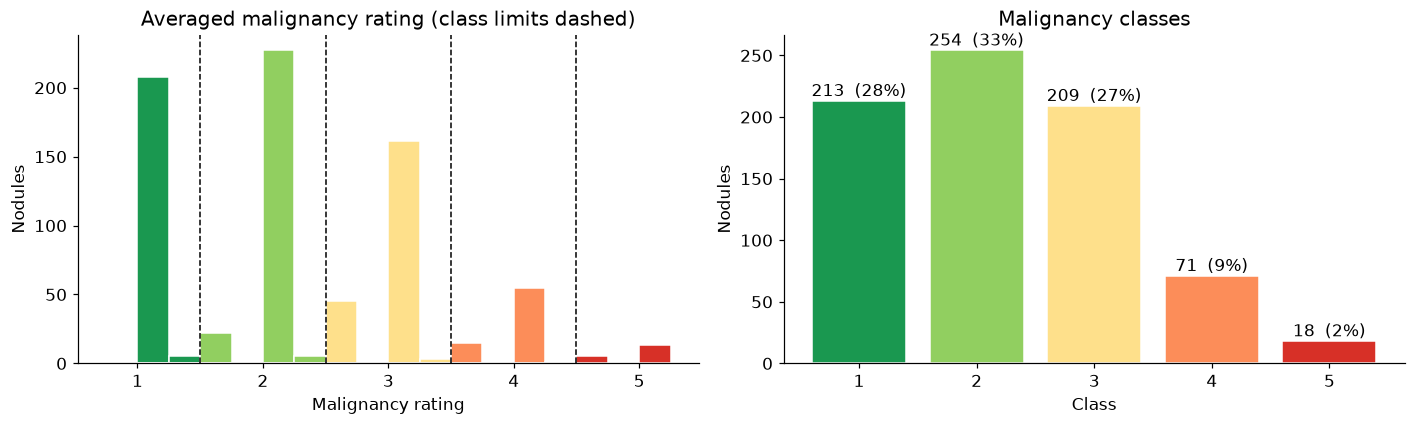

In [10]:
lab = df.dropna(subset=['malignancy_mean'])
counts = lab['malignancy_class'].astype(int).value_counts().reindex(U.MAL_LABELS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(0.75, 5.5, 0.25)
for c in U.MAL_LABELS:
    axes[0].hist(lab.loc[lab.malignancy_class == c, 'malignancy_mean'], bins=bins,
                 color=U.MALIGNANCY_COLORS[c - 1], edgecolor='white', label=f'class {c}')
for t in U.MAL_THRESHOLDS:
    axes[0].axvline(t, color='black', ls='--', lw=1)
axes[0].set(title='Averaged malignancy rating (class limits dashed)', xlabel='Malignancy rating', ylabel='Nodules')
axes[1].bar([str(c) for c in U.MAL_LABELS], counts.values, color=U.MALIGNANCY_COLORS, edgecolor='white')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 4, f'{v}  ({v / len(lab):.0%})', ha='center')
axes[1].set(title='Malignancy classes', xlabel='Class', ylabel='Nodules')
plt.tight_layout(); plt.show()

**Key finding — the target is ordered and imbalanced towards benign.** Most nodules are rated 1–3;
classes 4 and 5 together are only ~12% of the nodules (class 5: 18 nodules). Many averages fall
between two classes (e.g. 2.5 or 3.33), so the class boundary itself is noisy.

Consequences:
- Accuracy is misleading; we use the **competition's four metrics** — balanced accuracy, macro F1,
  quadratic weighted kappa (QWK) and mean absolute error (MAE).
- The target is **ordered**: predicting 4 for a 5 is a smaller error than 1 for a 5. Models that
  predict the *average rating* (a number) keep that order (Notebook 4).
- The rare suspicious classes need class weights / oversampling, and their results are uncertain.

### 5.2 What drives a malignancy rating?

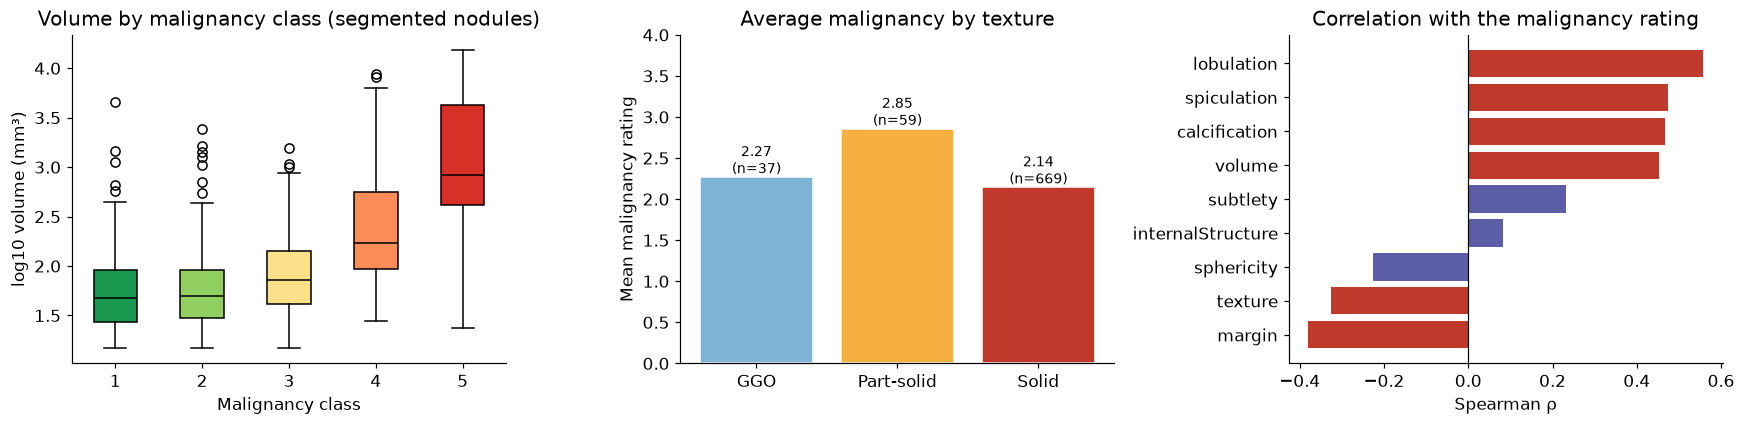

Malignancy class of the nodules < 3 mm: {1: 75, 2: 57, 3: 10, 4: 1}


In [11]:
seg = lab[~lab.is_small]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

data = [np.log10(seg.loc[seg.malignancy_class == c, 'Volume']) for c in U.MAL_LABELS]
box = axes[0].boxplot(data, tick_labels=[str(c) for c in U.MAL_LABELS], patch_artist=True, medianprops=dict(color='black'))
for patch, col in zip(box['boxes'], U.MALIGNANCY_COLORS):
    patch.set_facecolor(col)
axes[0].set(title='Volume by malignancy class (segmented nodules)', xlabel='Malignancy class', ylabel='log10 volume (mm³)')

tex = lab.groupby('texture_name')['malignancy_mean'].agg(['mean', 'count']).reindex(U.CLASS_NAMES)
axes[1].bar(tex.index, tex['mean'], color=[U.CLASS_COLORS[c] for c in tex.index], edgecolor='white')
for i, (m, n) in enumerate(zip(tex['mean'], tex['count'])):
    axes[1].text(i, m + 0.05, f'{m:.2f}\n(n={n})', ha='center', fontsize=9)
axes[1].set(title='Average malignancy by texture', ylabel='Mean malignancy rating', ylim=(0, 4))

others = [c for c in U.CHARACTERISTICS if c != 'malignancy']
rho = pd.Series({c: spearmanr(lab[f'{c}_mean'], lab.malignancy_mean, nan_policy='omit')[0] for c in others}
                | {'volume': spearmanr(lab.Volume, lab.malignancy_mean)[0], 'texture': spearmanr(lab.Text, lab.malignancy_mean)[0]}
                ).sort_values()
axes[2].barh(rho.index, rho.values, color=[U.COLOR_ACCENT if abs(v) > 0.3 else U.COLOR_NEUTRAL for v in rho.values])
axes[2].axvline(0, color='black', lw=0.8)
axes[2].set(title="Correlation with the malignancy rating", xlabel='Spearman ρ')
plt.tight_layout(); plt.show()
small = lab[lab.is_small].malignancy_class.astype(int).value_counts().sort_index()
print('Malignancy class of the nodules < 3 mm:', {int(k): int(v) for k, v in small.items()})

**Reading it.**
- **Size:** malignancy rises steadily with volume (ρ ≈ 0.45); nodules < 3 mm are almost all rated
  1–2.
- **Texture:** part-solid nodules have the highest average rating — the clinical rule that part-solid
  nodules are the most suspicious is visible in the data. (The texture *rating* correlates negatively
  because 5 = solid, not part-solid: the relation is not monotonic.)
- **Border and shape:** lobulation and spiculation correlate even more strongly than volume, and
  sharp margins (5 = sharp) and round shapes go with lower ratings. Calcification is positive because
  on this scale 6 means *absent* — calcified nodules are typically benign.
- These characteristics are the radiologist's **own reading**, not available for a new patient, so they
  are never used as features. They tell us what the image features must capture: **size, border
  shape and density** (Notebook 2).

### 5.3 How much do radiologists agree on malignancy?
The agreement between humans is the **realistic ceiling** for any model.

In [12]:
def reader_pairs(ratings: pd.Series) -> np.ndarray:
    pairs = []
    for s in ratings.dropna().astype(str):
        r = [int(x) for x in s.split(',') if x]
        pairs += [(r[i], r[j]) for i in range(len(r)) for j in range(i + 1, len(r))]
    return np.array(pairs)

mal_pairs = reader_pairs(lab.malignancy_ratings)
tex_pairs = []
per = U.load_ratings_per_radiologist().set_index(['LNDbID', 'RadID', 'FindingID'])
for _, r in df[df.AgrLevel >= 2].iterrows():
    keys = [(r.LNDbID, int(a), int(b)) for a, b in zip(str(r.RadID).split(','), str(r.RadFindingID).split(','))]
    t = [U.texture_to_class(v) for v in per.loc[keys, 'Text'] if v > 0]
    tex_pairs += [(t[i], t[j]) for i in range(len(t)) for j in range(i + 1, len(t))]
tex_pairs = np.array(tex_pairs)

agreement = pd.DataFrame({
    'pairs': [len(mal_pairs), len(tex_pairs)],
    'exact agreement': [np.mean(mal_pairs[:, 0] == mal_pairs[:, 1]), np.mean(tex_pairs[:, 0] == tex_pairs[:, 1])],
    'within ±1': [np.mean(np.abs(mal_pairs[:, 0] - mal_pairs[:, 1]) <= 1), np.nan],
    'QWK': [cohen_kappa_score(mal_pairs[:, 0], mal_pairs[:, 1], weights='quadratic'),
            cohen_kappa_score(tex_pairs[:, 0], tex_pairs[:, 1], weights='quadratic')],
    'mean abs. difference': [np.mean(np.abs(mal_pairs[:, 0] - mal_pairs[:, 1])), np.nan],
}, index=['malignancy (1–5)', 'texture (3 classes)'])
agreement.style.format({'pairs': '{:.0f}', 'exact agreement': '{:.0%}', 'within ±1': '{:.0%}',
                        'QWK': '{:.3f}', 'mean abs. difference': '{:.2f}'}, na_rep='—')

,pairs,exact agreement,within ±1,QWK,mean abs. difference
malignancy (1–5),309,41%,83%,0.527,0.79
texture (3 classes),309,93%,—,0.566,—


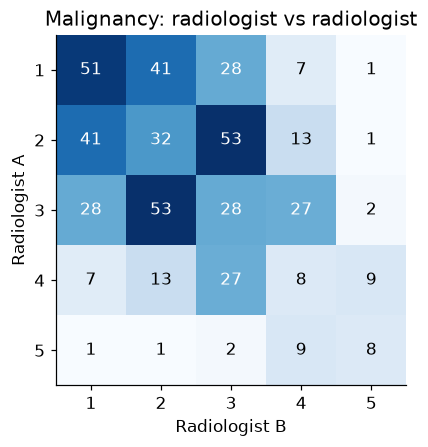

In [13]:
conf = pd.crosstab(pd.Series(mal_pairs[:, 0], name='Radiologist A'), pd.Series(mal_pairs[:, 1], name='Radiologist B'))
conf = conf.reindex(index=U.MAL_LABELS, columns=U.MAL_LABELS, fill_value=0)
conf = conf + conf.T - np.diag(np.diag(conf))          # unordered pairs → symmetric
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(conf.values, cmap='Blues')
ax.set_xticks(range(5), U.MAL_LABELS); ax.set_yticks(range(5), U.MAL_LABELS)
for i in range(5):
    for j in range(5):
        ax.text(j, i, conf.values[i, j], ha='center', va='center',
                color='white' if conf.values[i, j] > conf.values.max() / 2 else 'black')
ax.set(title='Malignancy: radiologist vs radiologist', xlabel='Radiologist B', ylabel='Radiologist A')
plt.tight_layout(); plt.show()

**Why this matters.**
- Radiologists give **the same malignancy rating in only ~41% of the pairs**, and QWK is only
  **≈ 0.53** — "moderate" agreement. Disagreements are almost always one step apart (2 vs 3, 3 vs 4).
- Texture (QWK ≈ 0.57) has a physical definition — density in HU — and is visible on the image;
  malignancy is a *prediction* that combines size, shape, texture and each reader's experience.
- **Consequences:** the label is noisy, so (1) the average of several readers is a better target than
  any single rating — models will learn the average; (2) radiologist-vs-radiologist agreement is the
  benchmark every model is compared with (Notebooks 4 and 6).

### 5.4 Do the five radiologists rate alike?

In [14]:
nod_per = U.load_ratings_per_radiologist().query('Nodule == 1').dropna(subset=['malignancy'])
by_rad = nod_per.groupby('RadGlobal')['malignancy'].agg(nodules='count', mean_rating='mean')
by_rad['% rated 1'] = nod_per.groupby('RadGlobal')['malignancy'].apply(lambda s: (s == 1).mean())
by_rad['% rated 4–5'] = nod_per.groupby('RadGlobal')['malignancy'].apply(lambda s: (s >= 4).mean())
by_rad.style.format({'mean_rating': '{:.2f}', '% rated 1': '{:.0%}', '% rated 4–5': '{:.0%}'})

,nodules,mean_rating,% rated 1,% rated 4–5
RadGlobal,,,,
1,278,2.25,27%,13%
2,119,2.09,39%,12%
3,105,1.57,69%,8%
4,227,2.72,13%,21%
5,301,2.18,28%,10%


**Reading it.** The radiologists do not use the scale in the same way: some give "1" much more
often than others. Part of this reflects the nodules each one happened to read, but it also shows a
**reader effect** — the same nodule can get a different label depending on who read it. Averaging
several readers dampens it; nodules read by a single radiologist carry it fully (Notebook 4 checks
the error on those nodules separately).

### 5.5 Fleischner category — context, but **not** a feature
The Fleischner category of a CT (0–3, follow-up recommendation) is **computed from** the size and
texture of its nodules. Using it as a feature would let the model peek at the answer (*target
leakage*), and it is not available for a new patient. We only use it to show the link with the target.

In [15]:
per_ct = lab.groupby('LNDbID')['malignancy_mean'].max().rename('highest malignancy in the CT').reset_index().merge(fleischner, on='LNDbID')
print(f"Spearman ρ (Fleischner, highest malignancy per CT) = {spearmanr(per_ct.Fleischner, per_ct['highest malignancy in the CT'])[0]:.2f}")
per_ct.groupby('Fleischner')['highest malignancy in the CT'].describe()[['count', 'mean', '50%']].round(2)

Spearman ρ (Fleischner, highest malignancy per CT) = 0.52


,count,mean,50%
Fleischner,,,
0,88.0,2.27,2.0
1,4.0,3.75,4.0
2,60.0,3.05,3.0
3,60.0,3.62,4.0


### 5.6 Scanners
Texture features depend on how the image was acquired. `LNDbAcqParams.csv` describes every CT,
**including the test CTs** — only acquisition metadata, no labels — so we can check that the test set
was acquired like the training set.

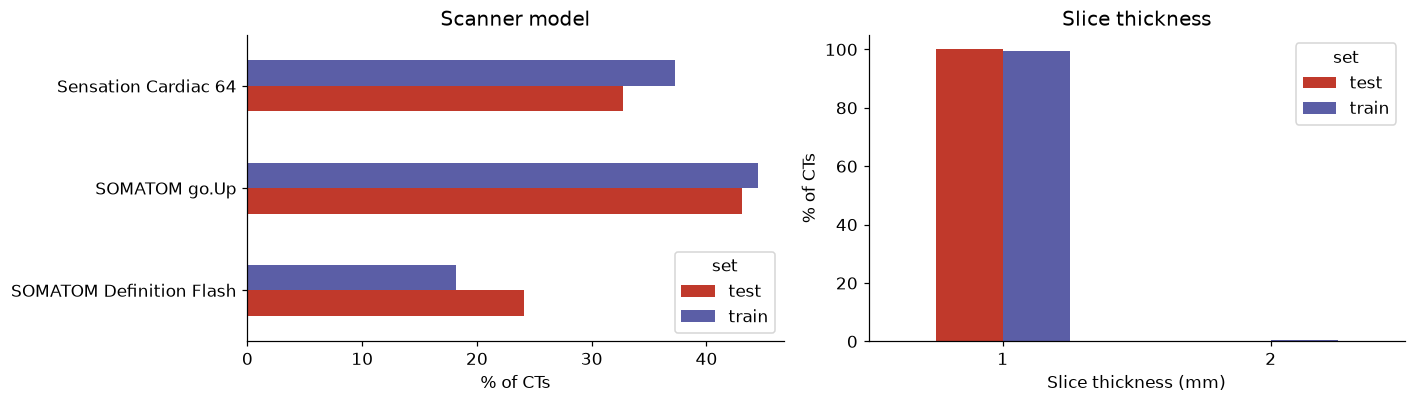

In [16]:
acq['set'] = np.where(acq.LNDbID.isin(test_nod.LNDbID), 'test', 'train')
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
pd.crosstab(acq.ManufacturerModelName, acq['set'], normalize='columns').mul(100).plot.barh(ax=axes[0], color=[U.COLOR_ACCENT, U.COLOR_NEUTRAL])
axes[0].set(xlabel='% of CTs', ylabel='', title='Scanner model')
pd.crosstab(acq.SliceThickness, acq['set'], normalize='columns').mul(100).plot.bar(ax=axes[1], rot=0, color=[U.COLOR_ACCENT, U.COLOR_NEUTRAL])
axes[1].set(xlabel='Slice thickness (mm)', ylabel='% of CTs', title='Slice thickness')
plt.tight_layout(); plt.show()

**Reading it.** Train and test CTs come from the same hospital, scanners and protocols, in similar
proportions — what the model learns on the training CTs applies to the test CTs. (LIDC-IDRI, used
in Notebooks 5–6, is different on all of these.)

### 5.7 Official folds

In [17]:
fold_tab = pd.crosstab(lab['fold'], lab['malignancy_class'].astype(int))
fold_tab['total'] = fold_tab.sum(axis=1)
fold_tab

malignancy_class,1,2,3,4,5,total
fold,,,,,,
0,53,70,58,14,4,199
1,57,65,48,19,3,192
2,53,57,48,20,6,184
3,50,62,55,18,5,190


Every fold contains every class (class 5 only a handful), so the **official folds** are used for
cross-validation. Folds are split **by CT**: all nodules of a patient stay in the same fold, and the
model is always evaluated on unseen patients.

### 5.8 The competition test set

In [18]:
per_ct_test = test_nod.groupby('LNDbID').size()
print(f'Test CTs       : {test_nod.LNDbID.nunique()}')
print(f'Test findings  : {len(test_nod)}')
print(f'Findings per CT: min {per_ct_test.min()}, max {per_ct_test.max()}')
print(f'Train nodules per CT: median {df.groupby("LNDbID").size().median():.0f}')

Test CTs       : 58
Test findings  : 2900
Findings per CT: min 50, max 50
Train nodules per CT: median 3


Every test CT has exactly 50 findings, while a training CT has a median of 3 nodules. Most test
findings are therefore very likely **decoys** (non-nodules or random points) mixed with the real
nodules so that their locations are not revealed. We do not know how the competition scores them.

**Design consequence:** at test time there are no radiologist masks. Features must be computed **in
the same way for train and test** — from a region found automatically around the centroid
(Notebook 2).

## 6. Save the working dataset

In [19]:
cols = ['LNDbID', 'FindingID', 'x', 'y', 'z', 'Volume', 'is_small', 'AgrLevel', 'RadN', 'n_readers', 'readers',
        'malignancy_ratings', 'malignancy_mean', 'malignancy_sd', 'malignancy_class',
        'Text', 'texture_class', 'texture_name', 'mask_rad_id', 'mask_finding_id', 'fold']
out_path = U.OUTPUT_DIR / 'working_dataset.csv'
df[cols].to_csv(out_path, index=False)
print(f'Saved {len(df)} nodules → {out_path.relative_to(U.ROOT)}')

Saved 768 nodules → outputs/working_dataset.csv


---
## Summary

| Finding | Decision for the next notebooks |
|---|---|
| Malignancy (1–5) is in `chars_trainNodules.csv`, aligned **by position** with `trainNodules.csv` (radiologist IDs differ) | Joined by position after checks; label = average of the readers, class = rounded half-up |
| Most nodules are benign (1–3); class 5 is rare | The competition's four metrics; class weights / oversampling; uncertain results on rare classes |
| The target is ordered and is an average | Models predict the average rating (Notebook 4) |
| Radiologists agree only moderately (QWK ≈ 0.53) and use the scale differently | Noisy labels; human agreement = benchmark |
| Size, texture and border shape drive the ratings | Features must describe size, shape and density (Notebook 2) |
| Fleischner is computed from the nodules | Excluded as a feature (target leakage) |
| Test set: centroids only, 50 per CT; same scanners as train | Same automatic pipeline for train and test |
| Folds are split by CT | Official folds for all LNDb validation |

**Next → Notebook 2:** extract features around each nodule centroid.

---
## 7. Data issues across the whole project — overview

A single reference for every data problem found in the project, including those discovered later
(Notebooks 2–6). Each row says what the problem is, why it matters, what we did and where.

### 7.1 Issues we handled
| # | Issue | Why it matters | What we did | Where |
|---|---|---|---|---|
| 1 | **Wrong dataset version**: the LNDb v2 tables only contain texture; malignancy is in `chars_trainNodules.csv` (v3/v4) | Our first model predicted texture — the first competition submission scored QWK ≈ −0.06 | Target changed to malignancy; texture model kept as appendix; LIDC-IDRI used meanwhile, now extra data | NB 1, NB 6, appendix |
| 2 | **Misaligned radiologist IDs** between `trainNodules.csv` and `chars_trainNodules.csv` | A join on the ID would lose or mismatch > 50% of the ratings | Rows joined by position after checking CT and finding on every row | NB 1 §3.1 |
| 3 | **Incomplete download**: 13 training CTs missing after the first extraction of `data0.rar` | 709 nodules instead of 768 in an early version | Pipeline detects and reports incomplete CTs; archive re-extracted, all 212 CTs used | NB 2 |
| 4 | **Imbalanced, ordered target** (class 5 = 2%) | Accuracy misleads; rare classes uncertain | Four competition metrics, class weights / SMOTE, prevalence cut-offs, bootstrap CIs | NB 1 §5.1, NB 4 |
| 5 | **Subjective labels**: radiologists agree with QWK ≈ 0.53 on malignancy, and use the scale differently | No perfect ground truth | Target = average of readers; human agreement as benchmark | NB 1 §5.3–5.4, NB 4 |
| 6 | **Single-reader labels** (most nodules) | One opinion, not an average | Reported separately | NB 4 |
| 7 | **Unrated characteristics coded as 0**; 3 nodules without malignancy | 0 would read as "lowest rating" | 0 → missing; unrated nodules excluded from training | NB 1 §4 |
| 8 | **Nodules < 3 mm**: no mask, placeholder volume | Volume is not a measurement | Kept and flagged; checked separately | NB 1, NB 4 |
| 9 | **Test set without masks**, 50 positions per CT | Train and test must be processed alike | Same automatic segmentation for train and test | NB 1 §5.8, NB 2 |
| 10 | **Imperfect automatic segmentation** (median Dice ≈ 0.68) | Features of a slightly wrong region | Lung mask + morphological opening; cost measured | NB 2, NB 4 |
| 11 | **Different voxel spacings** | Texture depends on resolution | Resampling to 1 mm | NB 2 |
| 12 | **1136 features for ~765 nodules** | Overfitting | Selection inside cross-validation; regularised models | NB 3, NB 4 |
| 13 | **Skewed, redundant features** | Outliers dominate; repeated information | Rank statistics, quantile transform, redundancy filter | NB 3 |
| 14 | **Leakage risks** (Fleischner; several nodules per patient; test labels) | Optimistic or invalid results | Fleischner excluded; folds by CT/patient; no test CT in any label file | NB 1, NB 3, NB 4 |
| 15 | **Domain shift LIDC ↔ LNDb** (other country, scanners, readers; a much more malignant population) | LIDC data can mislead an LNDb model | Measured; LIDC used as extra data with lower weight, cut-offs from LNDb | NB 5, NB 6 |

### 7.2 Limitations we could not remove
| Limitation | Consequence |
|---|---|
| **Malignancy is a suspicion, not a diagnosis** (no biopsy) | The model reproduces radiologists' judgement, not confirmed cancer |
| **One hospital** for the target data (CHUSJ, Porto) | Generalisation to other centres is untested |
| **No demographic data** in the annotation tables | Fairness by age or sex cannot be audited |
| **Decoys in the test set** | How they are scored is not public |
| **Licence CC BY-NC-ND 4.0** | Non-commercial use, with citation, **no redistribution** → no CT, mask or feature table in the code repository |